In [1]:
import sys
import matplotlib
import ipympl
import ipywidgets

print("Python:", sys.executable)
print("Matplotlib:", matplotlib.__version__)
print("ipympl:", ipympl.__version__)
print("ipywidgets:", ipywidgets.__version__)

Python: c:\devel\anaconda3\envs\mantta2\python.exe
Matplotlib: 3.9.4
ipympl: 0.9.8
ipywidgets: 8.1.9


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from spectral import envi
# import tools
from matplotlib.patches import Rectangle
from stitching_functions import convert_to_reflectance

(5, 512, 204)


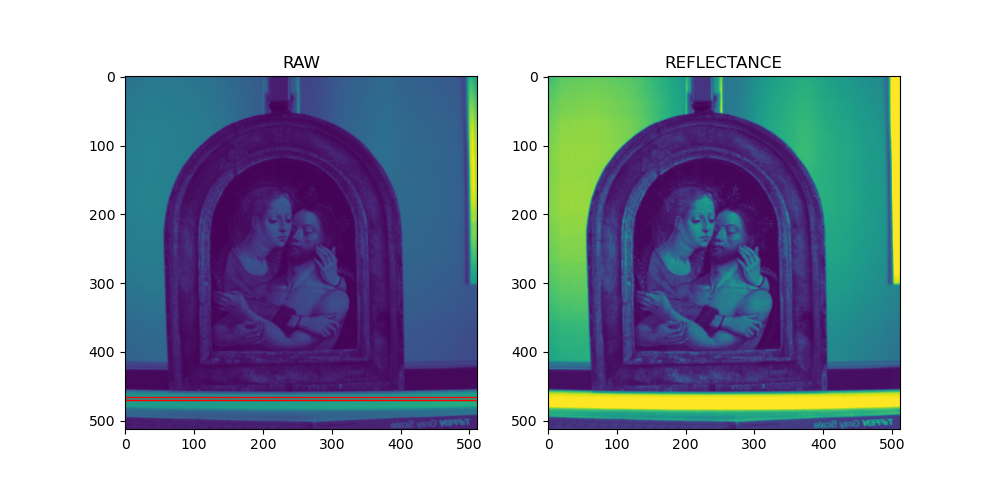

In [3]:
folder = r'../../IQ_raw/pieta'  # folder of given acquisition
num = 921  # number corresponding to the acquisition

path_raw = f"{folder}/{num}/capture/{num}.hdr"
path_dark = f"{folder}/{num}/capture/DARKREF_{num}.hdr"

# Opening hsi cube and dark reference.
cube_og = envi.open(path_raw).asarray()
dark = envi.open(path_dark).asarray()
# cube_og.shape, dark.shape

y, pxls = 465, 5  # y of white reference + how many rows for taking the average white
band = 100 

cube = cube_og.transpose(1,0,2) # Transposing to be "right side up"

fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(10, 5))
ax[0].imshow(cube[:, :, band])  # Plotting to check
ax[0].add_patch(Rectangle(xy=(0,y), width=512, height=pxls, ec='red', fc='none', ls='-', lw=1))  # Rectangle to white ref area
ax[0].set_title('RAW')

# Snip the white reference
white = cube[y:y+pxls]
print(white.shape)
white = np.average(white, axis = 0, keepdims=True)  # avg white

refl = convert_to_reflectance(raw=cube, white=white, dark=dark)
ax[1].imshow(refl[:, :, band], vmax=1)
ax[1].set_title('REFLECTANCE')

plt.show()

In [4]:
import ipywidgets as widgets
display(widgets.IntSlider())

IntSlider(value=0)

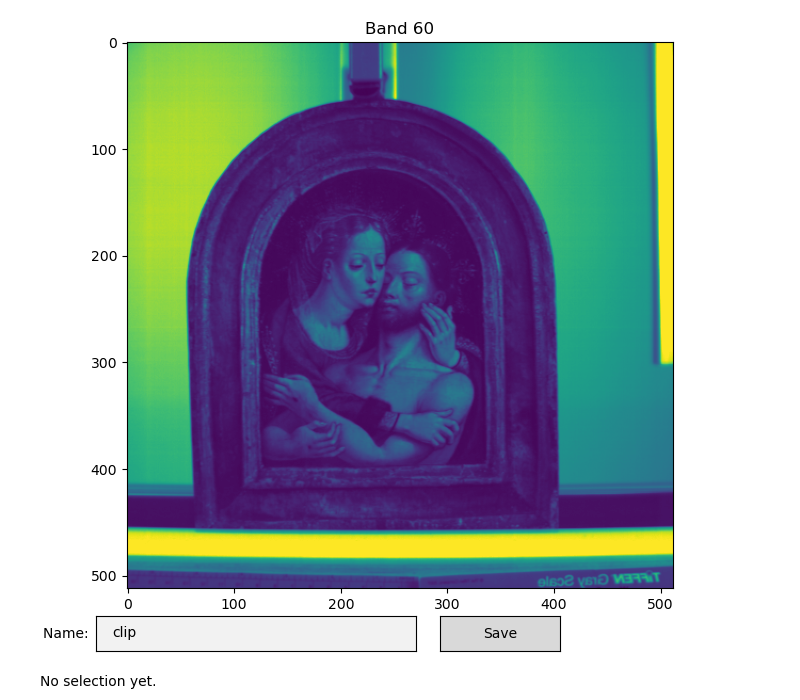

In [5]:
from cube_tools import CubeClipper
%matplotlib widget

band = 60  # The band you want displayed
savepath = 'clippings'  # path to folder where the clips are saved. 
clipper = CubeClipper(refl, band=60, out_dir=savepath)